# 01 – Data exploration of one patient (PedsLeukBM, `A6BB...`)

Exploration of **all files** of patient `A6BBC91AE73DD21C0533F735470A9CD0` from the PedsLeukBM dataset
(Zenodo 10.5281/zenodo.15490664, DICOM WSI + DICOM bulk annotations):

1. **File inventory** – what is in the folder and how the files reference each other
2. **Image pyramid** – all resolution levels, tiling, pixel spacing, exact downsampling factors
3. **Coordinate systems** – image pixels vs. slide millimetres, mapping between levels
4. **Annotation files** – DICOM structure, graphic type, measurements
5. **Integrity checks** – boxes vs. ROIs, duplicate ids
6. **Annotation protocol** – 5 annotation sessions vs. consensus, inter-rater agreement
7. **Putting it together** – ROIs and cells on the full-resolution image, cell gallery per class
8. **Statistics** – classes, box sizes, spatial distribution
9. **Clinical data** – DICOM clinical tags and lab values
10. **Findings & open questions**

All image access is **tile-wise** (one 1024x1024 JPEG frame at a time, random access via the Extended Offset Table),
so the 5.4 GB full-resolution file is never loaded as a whole.

In [1]:
from pathlib import Path
import math, re, collections

import numpy as np, pandas as pd, pydicom
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pydicom.pixels import pixel_array          # pydicom >= 3: decode a single frame straight from disk
from IPython.display import display

# ---- configuration ----
DATA_DIR = Path("../Data")
PATIENT_ID = "A6BBC91AE73DD21C0533F735470A9CD0"
LAB_FILE = DATA_DIR / "lab_values_sample.csv"
# -----------------------

PDIR = DATA_DIR / PATIENT_ID
pd.set_option("display.width", 220, "display.max_columns", 50, "display.max_rows", 120, "display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 11})

## 1. File inventory
File names follow `<PatientID>-<Modality>-<SeriesDescription>-<SOPInstanceUID>.dcm`.
Only headers are read here (`stop_before_pixels=True`).

In [2]:
def kind(ds):
    if ds.Modality == "SM":
        return ds.ImageType[2]                                 # VOLUME / THUMBNAIL / OVERVIEW / LABEL
    return ds.SeriesDescription

inv = []
for f in sorted(PDIR.glob("*.dcm")):
    h = pydicom.dcmread(f, stop_before_pixels=True)
    inv.append({"modality": h.Modality, "kind": kind(h), "size_MB": round(f.stat().st_size / 1e6, 2),
                "series#": h.get("SeriesNumber"), "instance#": h.get("InstanceNumber"),
                "sop_uid_tail": h.SOPInstanceUID[-12:],
                "references": h.ReferencedImageSequence[0].ReferencedSOPInstanceUID[-12:] if "ReferencedImageSequence" in h else "",
                "path": f})
inv = pd.DataFrame(inv).sort_values(["modality", "size_MB"], ascending=[False, False]).reset_index(drop=True)
display(inv.drop(columns="path"))
print("total:", round(inv.size_MB.sum() / 1e3, 2), "GB in", len(inv), "files;",
      "studies:", {str(pydicom.dcmread(p, stop_before_pixels=True).StudyInstanceUID)[-8:] for p in inv.path})

,modality,kind,size_MB,series#,instance#,sop_uid_tail,references
0,SM,VOLUME,5403.73,1,0,909698360370,
1,SM,VOLUME,321.09,1,1,781886860911,
2,SM,VOLUME,29.74,1,2,118526447221,
3,SM,VOLUME,1.84,1,3,178302569957,
4,SM,VOLUME,0.17,1,4,781793930540,
5,SM,THUMBNAIL,0.17,1,5,555107633181,
6,SM,OVERVIEW,0.08,1,6,339592150470,
7,ANN,Cell bounding boxes with cell type labels; annotation session: 0,0.04,33,1,991231532557,909698360370
8,ANN,Cell bounding boxes with cell type labels; annotation session: 1,0.04,33,2,546324231815,909698360370
9,ANN,Cell bounding boxes with consensus cell type labels,0.04,33,5,208180843212,909698360370


total: 5.76 GB in 14 files; studies: {'82530941'}


**Reading the table:** 7 SM files (slide microscopy images) and 7 ANN files (annotations).
Every ANN file references the **same** SM instance – the largest file, i.e. the full-resolution level.

## 2. Image pyramid

A DICOM whole-slide image is stored as **one file per resolution level**. Each level is a pixel matrix of
`TotalPixelMatrixColumns x TotalPixelMatrixRows`, cut into JPEG tiles of `Columns x Rows` (here 1024x1024) that are stored
row-major (`DimensionOrganizationType = TILED_FULL`). The helper class below reads any rectangular region of any level
by decoding only the tiles it touches.

In [3]:
class SMLevel:
    # one SM file = one pyramid level; read_region() decodes only the tiles it needs
    def __init__(self, path):
        self.path = Path(path)
        h = self.hdr = pydicom.dcmread(path, stop_before_pixels=True)
        self.W, self.H = int(h.TotalPixelMatrixColumns), int(h.TotalPixelMatrixRows)
        self.tw, self.th = int(h.Columns), int(h.Rows)
        self.n = int(h.NumberOfFrames)
        self.gcols, self.grows = math.ceil(self.W / self.tw), math.ceil(self.H / self.th)
        pm = h.SharedFunctionalGroupsSequence[0].PixelMeasuresSequence[0]
        ps = pm.get("PixelSpacing")                        # [row spacing (y), column spacing (x)] in mm; missing for OVERVIEW
        self.ps_y, self.ps_x = (float(ps[0]), float(ps[1])) if ps else (np.nan, np.nan)
        self.kind = kind(h)

    def tile(self, i):
        return pixel_array(self.path, index=i) if self.n > 1 else pixel_array(self.path)

    def read_region(self, x0, y0, w, h):
        # RGB crop in this level's pixel coordinates (clipped to the image; outside = white)
        x0, y0 = int(max(x0, 0)), int(max(y0, 0))
        x1, y1 = int(min(x0 + w, self.W)), int(min(y0 + h, self.H))
        out = np.full((y1 - y0, x1 - x0, 3), 255, np.uint8)
        for r in range(y0 // self.th, (y1 - 1) // self.th + 1):
            for c in range(x0 // self.tw, (x1 - 1) // self.tw + 1):
                t = self.tile(r * self.gcols + c)
                ty0, tx0 = r * self.th, c * self.tw
                sy0, sx0, sy1, sx1 = max(y0, ty0), max(x0, tx0), min(y1, ty0 + self.th), min(x1, tx0 + self.tw)
                out[sy0 - y0:sy1 - y0, sx0 - x0:sx1 - x0] = t[sy0 - ty0:sy1 - ty0, sx0 - tx0:sx1 - tx0]
        return out

    def full(self):
        return self.read_region(0, 0, self.W, self.H)

    def file_tag(self):
        # short name of the file this level comes from: ...<last 8 digits of SOP UID>.dcm (size)
        return f"...{self.path.stem[-8:]}.dcm ({self.path.stat().st_size / 1e6:,.1f} MB)"

levels = [SMLevel(p) for p in inv[inv.modality == "SM"].path]
FULL = max((l for l in levels if l.kind == "VOLUME"), key=lambda l: l.W)
VOLUMES = sorted((l for l in levels if l.kind == "VOLUME"), key=lambda l: -l.W)

pyr = pd.DataFrame([{
    "kind": l.kind, "ImageType": "/".join(l.hdr.ImageType), "W x H [px]": f"{l.W:,} x {l.H:,}",
    "tile": f"{l.tw}x{l.th}", "grid": f"{l.gcols}x{l.grows}", "frames": l.n,
    "spacing x [um]": round(l.ps_x * 1000, 4), "spacing y [um]": round(l.ps_y * 1000, 4),
    "factor (matrix W ratio)": round(FULL.W / l.W, 4), "factor (spacing ratio)": round(l.ps_x / FULL.ps_x, 4),
    "size_MB": round(l.path.stat().st_size / 1e6, 1),
    "codec": l.hdr.file_meta.TransferSyntaxUID.name, "colour": l.hdr.PhotometricInterpretation,
} for l in sorted(levels, key=lambda l: -l.W)])
display(pyr)
for l in VOLUMES:
    assert l.gcols * l.grows == l.n, "every level is a full tiling"

,kind,ImageType,W x H [px],tile,grid,frames,spacing x [um],spacing y [um],factor (matrix W ratio),factor (spacing ratio),size_MB,codec,colour
0,VOLUME,ORIGINAL/PRIMARY/VOLUME/NONE,"186,257 x 446,170",1024x1024,182x436,79352,0.1105,0.1107,1.0000,1.0000,5403.7,JPEG Baseline (Process 1),YBR_FULL_422
1,VOLUME,DERIVED/PRIMARY/VOLUME/RESAMPLED,"46,564 x 111,542",1024x1024,46x109,5014,0.4422,0.4429,4.0000,4.0000,321.1,JPEG Baseline (Process 1),YBR_FULL_422
2,VOLUME,DERIVED/PRIMARY/VOLUME/RESAMPLED,"11,641 x 27,885",1024x1024,12x28,336,1.7687,1.7716,16.0001,16.0000,29.7,JPEG Baseline (Process 1),YBR_FULL_422
3,VOLUME,DERIVED/PRIMARY/VOLUME/RESAMPLED,"2,910 x 6,971",1024x1024,3x7,21,7.0749,7.0863,64.0058,64.0000,1.8,JPEG Baseline (Process 1),YBR_FULL_422
4,VOLUME,DERIVED/PRIMARY/VOLUME/RESAMPLED,"727 x 1,742",1024x1024,1x2,2,28.2994,28.3453,256.1994,256.0000,0.2,JPEG Baseline (Process 1),YBR_FULL_422
5,THUMBNAIL,ORIGINAL/PRIMARY/THUMBNAIL/NONE,"727 x 1,743",727x1743,1x1,1,28.3031,28.3490,256.1994,256.0336,0.2,JPEG Baseline (Process 1),YBR_FULL_422
6,OVERVIEW,ORIGINAL/PRIMARY/OVERVIEW/NONE,"535 x 1,083",535x1083,1x1,1,NaN,NaN,348.1439,NaN,0.1,JPEG Baseline (Process 1),YBR_FULL_422


- **5 VOLUME levels** form the pyramid: full resolution (`ORIGINAL`, ~0.11 um/px, i.e. a 40x-like scan) and 4 levels
  `DERIVED/RESAMPLED` by **exactly 4x, 16x, 64x, 256x** (both the pixel-matrix ratio and the spacing ratio give 4^k).
- `THUMBNAIL` is a single-frame copy of roughly the 256x level, `OVERVIEW` is the low-resolution macro photo of the whole glass slide (no pixel spacing).
- All frames are JPEG baseline in `YBR_FULL_422`; pydicom converts them to RGB on decode.
- The full-res level would be ~250 GB as raw RGB – it can only ever be read tile by tile.

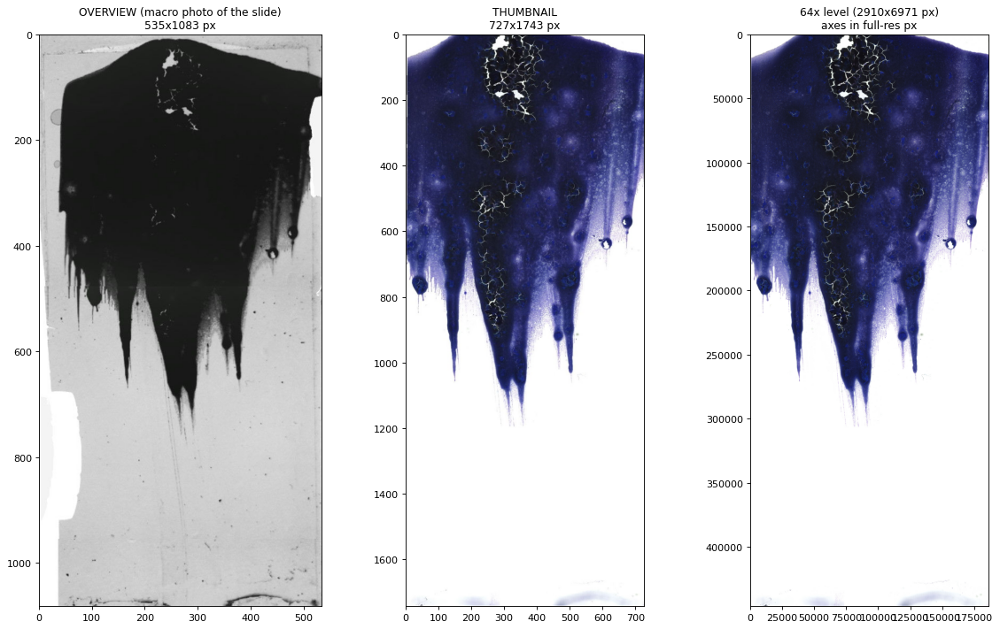

In [4]:
ov = next(l for l in levels if l.kind == "OVERVIEW")
thumb = next(l for l in levels if l.kind == "THUMBNAIL")
L64 = next(l for l in VOLUMES if round(FULL.W / l.W) == 64)

fig, axs = plt.subplots(1, 3, figsize=(15, 9))
axs[0].imshow(ov.full()); axs[0].set_title(f"OVERVIEW (macro photo of the slide)\n{ov.W}x{ov.H} px")
axs[1].imshow(thumb.full()); axs[1].set_title(f"THUMBNAIL\n{thumb.W}x{thumb.H} px")
img64 = L64.full()
axs[2].imshow(img64, extent=(0, FULL.W, FULL.H, 0)); axs[2].set_title(f"64x level ({L64.W}x{L64.H} px)\naxes in full-res px")
plt.tight_layout(); plt.show()

### Same spot at every level
To see what each level actually resolves: a fixed 225 x 225 um field (the size of one annotation ROI, see below),
shown at every pyramid level. Cells are ~10-15 um wide, so they are only recognisable at the 1x and 4x levels.

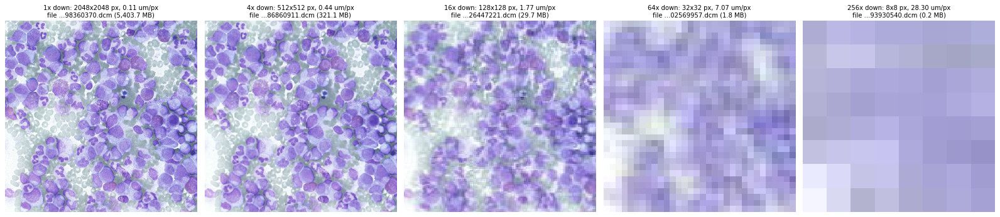

In [5]:
roi_file = inv[inv.kind.str.startswith("Monolayer")].path.iloc[0]
_r = np.frombuffer(pydicom.dcmread(roi_file).AnnotationGroupSequence[0].PointCoordinatesData, "<f4").reshape(-1, 4, 2)
FX0, FY0 = _r[0].min(axis=0)                     # first ROI, full-res px
SIDE = 2048                                       # full-res px = 225 um

level_crops = {}
fig, axs = plt.subplots(1, len(VOLUMES), figsize=(4 * len(VOLUMES), 4.4))
for a, l in zip(axs, VOLUMES):
    f = FULL.W / l.W
    crop = level_crops[round(f)] = l.read_region(FX0 / f, FY0 / f, math.ceil(SIDE / f), math.ceil(SIDE / f))
    a.imshow(crop, interpolation="nearest")
    a.set_title(f"{round(f)}x down: {crop.shape[1]}x{crop.shape[0]} px, {l.ps_x*1000:.2f} um/px\nfile {l.file_tag()}", fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

### Same spot at native size (no stretching)
The figure above stretches every crop to the same display size, which makes the small levels look blurry.
Here every crop shows the **same 226 um field**, drawn **1 image pixel = 1 screen pixel** (the 2048 px wide 1x crop sits in a scroll box).
Small levels are then tiny, but sharp-looking – the detail is still not there: at 64x a whole cell is ~2 px.


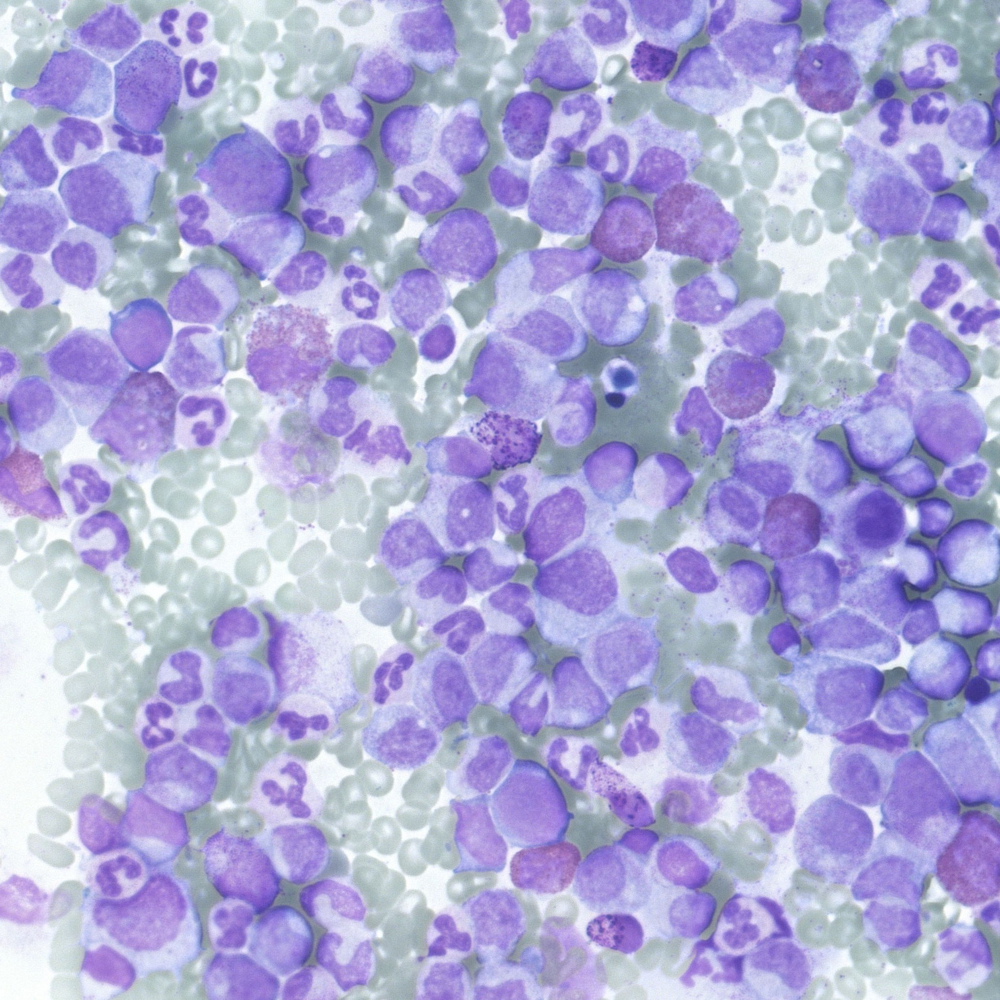
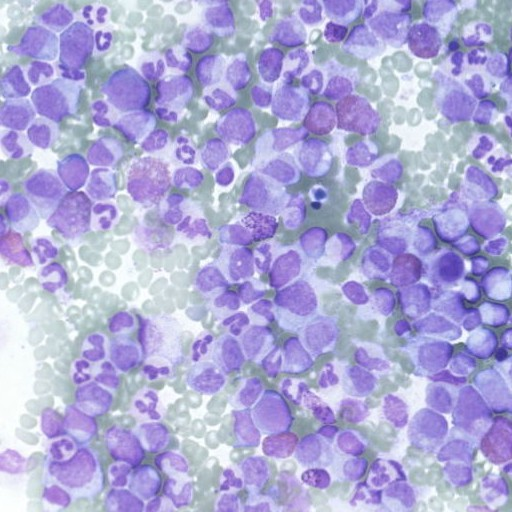
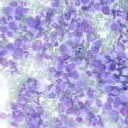
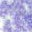

In [6]:
import base64, io
from IPython.display import HTML
from PIL import Image

def png_tag(arr):
    buf = io.BytesIO(); Image.fromarray(arr).save(buf, format="JPEG", quality=90)    # JPEG: the source tiles are JPEG anyway
    h, w = arr.shape[:2]
    # explicit width/height = native size, so neither the browser nor Jupyter rescales it
    return f'<img src="data:image/jpeg;base64,{base64.b64encode(buf.getvalue()).decode()}" width="{w}" height="{h}" style="max-width:none">'

HTML('<div style="display:flex;gap:24px;align-items:flex-end;overflow-x:auto;max-height:2150px">' + "".join(
    f'<figure style="margin:0;flex:none">{png_tag(a)}<figcaption style="font-size:11px">{f}x ({a.shape[1]}x{a.shape[0]} px) – file {l.file_tag()}</figcaption></figure>'
    for (f, a), l in zip(level_crops.items(), VOLUMES)) + "</div>")

### Zoom series: the right level for every zoom
This is how a slide viewer uses the pyramid: the output window has a **fixed size** (`WIN` px), and for every zoom step it reads
from the level whose resolution fits. Each step 4x closer = the next finer level = a field 4x smaller in each direction,
so **every panel has real pixels and stays sharp**. The red square marks the field of the next panel.

Change `CENTER` (full-res px, e.g. the centre of a cell from `cons`) and `WIN` to zoom somewhere else.

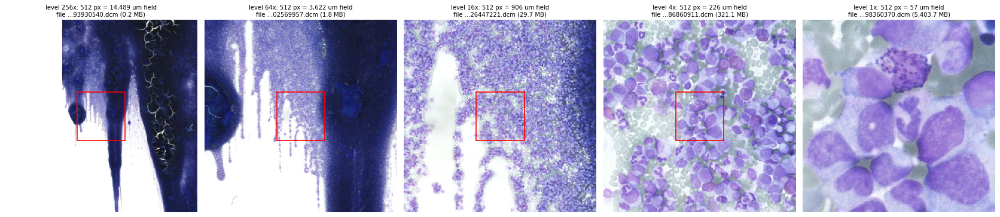

In [7]:
CENTER = (FX0 + 1024, FY0 + 1024)       # full-res px; default: centre of the first ROI
WIN = 512                               # output size of every panel in px

def read_window(lvl, cx, cy, size):
    # size x size crop of a level centred on (cx, cy) in *this level's* px; white outside the image
    x0, y0 = int(round(cx - size / 2)), int(round(cy - size / 2))
    out = np.full((size, size, 3), 255, np.uint8)
    sx0, sy0 = max(x0, 0), max(y0, 0)
    sx1, sy1 = min(x0 + size, lvl.W), min(y0 + size, lvl.H)
    if sx1 > sx0 and sy1 > sy0:
        out[sy0 - y0:sy1 - y0, sx0 - x0:sx1 - x0] = lvl.read_region(sx0, sy0, sx1 - sx0, sy1 - sy0)
    return out

steps = VOLUMES[::-1]                   # coarse -> fine: 256x, 64x, 16x, 4x, 1x
fig, axs = plt.subplots(1, len(steps), figsize=(4.2 * len(steps), 4.8))
for k, (a, l) in enumerate(zip(axs, steps)):
    f = FULL.W / l.W
    a.imshow(read_window(l, CENTER[0] / f, CENTER[1] / f, WIN), interpolation="nearest")
    if k < len(steps) - 1:                                       # where the next (4x finer) panel looks
        nxt = WIN * (FULL.W / steps[k + 1].W) / f
        a.add_patch(Rectangle((WIN / 2 - nxt / 2, WIN / 2 - nxt / 2), nxt, nxt, fill=False, ec="red", lw=1.5))
    field_um = WIN * l.ps_x * 1000
    a.set_title(f"level {round(f)}x: {WIN} px = {field_um:,.0f} um field\nfile {l.file_tag()}", fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Coordinate systems – how to say *where* something is

**In plain words:** an image file is just a big grid of pixels. To point at a cell you need a position, and DICOM allows two ways to give one:

| | **2D = image pixels** | **3D = slide millimetres** |
|---|---|---|
| unit | pixel (column x, row y), counted from the top-left corner | mm on the physical glass slide |
| refers to | **one particular file** (one resolution level) | the glass slide itself, independent of any file |
| example | "x = 26100, y = 196503 in the 1x file" | "25.2 mm along X, 4.7 mm along Y on the glass" |
| same spot in another level | different numbers (divide by 4, 16, 64, 256) | same numbers |
| 3rd value | – | Z = focus depth; only used by scanners that take several focus planes. Here there is only one plane, so Z = 0 |

Every annotation file says which system it uses in `AnnotationCoordinateType`. The cell below reads that for all 7 files.

In [8]:
ann_files = inv[inv.modality == "ANN"]
for p in ann_files.path:
    a = pydicom.dcmread(p, stop_before_pixels=True)
    print(f"{a.SeriesDescription[:55]:56s} CoordinateType={a.AnnotationCoordinateType}  "
          f"PixelOrigin={a.PixelOriginInterpretation}  references full-res: "
          f"{a.ReferencedImageSequence[0].ReferencedSOPInstanceUID == FULL.hdr.SOPInstanceUID}")

o = FULL.hdr.TotalPixelMatrixOriginSequence[0]
print("\nfull-res origin on slide [mm]:", float(o.XOffsetInSlideCoordinateSystem), float(o.YOffsetInSlideCoordinateSystem),
      "| ImageOrientationSlide:", [float(v) for v in FULL.hdr.ImageOrientationSlide])
print(f"scanned area: {FULL.W * FULL.ps_x:.2f} mm x {FULL.H * FULL.ps_y:.2f} mm "
      f"(ImagedVolume {float(FULL.hdr.ImagedVolumeWidth):.2f} x {float(FULL.hdr.ImagedVolumeHeight):.2f} mm)")
print("scanner:", FULL.hdr.get("Manufacturer"), FULL.hdr.get("ManufacturerModelName"),
      "| illumination:", FULL.hdr.OpticalPathSequence[0].IlluminationTypeCodeSequence[0].CodeMeaning)

Cell bounding boxes with cell type labels; annotation s  CoordinateType=2D  PixelOrigin=VOLUME  references full-res: True
Cell bounding boxes with cell type labels; annotation s  CoordinateType=2D  PixelOrigin=VOLUME  references full-res: True
Cell bounding boxes with consensus cell type labels      CoordinateType=2D  PixelOrigin=VOLUME  references full-res: True
Cell bounding boxes with cell type labels; annotation s  CoordinateType=2D  PixelOrigin=VOLUME  references full-res: True
Cell bounding boxes with cell type labels; annotation s  CoordinateType=2D  PixelOrigin=VOLUME  references full-res: True
Cell bounding boxes with cell type labels; annotation s  CoordinateType=2D  PixelOrigin=VOLUME  references full-res: True
Monolayer regions of interest for cell classification    CoordinateType=2D  PixelOrigin=VOLUME  references full-res: True

full-res origin on slide [mm]: 3.43771455445546 1.84354934210526 | ImageOrientationSlide: [-0.0, 1.0, 0.0, 1.0, 0.0, 0.0]
scanned area: 20.59 mm 

**What the output says**
- `CoordinateType=2D` – all annotation files use **pixel** coordinates, not mm.
- `PixelOrigin=VOLUME` – pixels are counted from the top-left corner of the **whole** image.
  (The alternative, `FRAME`, would count from 0 again inside every 1024 x 1024 tile.)
- `references full-res: True` – the pixels are pixels of the **1x file** (5.4 GB). For a smaller level, divide by its factor.
- The `origin` / `ImageOrientationSlide` lines say where the image lies on the glass and that it is rotated by 90 deg
  (image x runs along slide Y). They are only needed to convert to mm.

The next cell takes one concrete rectangle – ROI 100 – and writes it in every level's pixels and in slide mm.

In [9]:
def to_slide_mm(x, y, lvl=FULL):
    # image pixel (x=col, y=row) of a VOLUME level -> slide coordinates (mm), DICOM WSI convention
    o = lvl.hdr.TotalPixelMatrixOriginSequence[0]
    row_dir, col_dir = np.array(lvl.hdr.ImageOrientationSlide[:3], float), np.array(lvl.hdr.ImageOrientationSlide[3:], float)
    p = np.array([float(o.XOffsetInSlideCoordinateSystem), float(o.YOffsetInSlideCoordinateSystem), 0.0])
    return p + x * lvl.ps_x * row_dir + y * lvl.ps_y * col_dir

ex = dict(x=float(FX0), y=float(FY0), w=SIDE, h=SIDE)          # ROI 100 as stored in the annotation file
display(pd.DataFrame([{
    "level": f"{round(FULL.W / l.W)}x", "file": l.file_tag(),
    "x": round(ex["x"] / (FULL.W / l.W), 1), "y": round(ex["y"] / (FULL.W / l.W), 1),
    "w": round(ex["w"] / (FULL.W / l.W), 1), "h": round(ex["h"] / (FULL.W / l.W), 1),
} for l in VOLUMES]).set_index("level"))
print("top-left corner on the glass slide [mm] (X, Y, Z):", to_slide_mm(ex["x"], ex["y"]).round(3))

,file,x,y,w,h
level,,,,,
1x,"...98360370.dcm (5,403.7 MB)",26100.0,196503.0,2048.0,2048.0
4x,...86860911.dcm (321.1 MB),6525.0,49125.5,512.0,512.0
16x,...26447221.dcm (29.7 MB),1631.2,12281.4,128.0,128.0
64x,...02569957.dcm (1.8 MB),407.8,3070.1,32.0,32.0
256x,...93930540.dcm (0.2 MB),101.9,767.0,8.0,8.0


top-left corner on the glass slide [mm] (X, Y, Z): [25.195  4.729  0.   ]


**Take-away:** the annotation stores the 1x numbers (first row). The same ROI in the 16x file starts at pixel (1631, 12281) and is 128 px wide –
just divide by 16. The mm position is the same for every level; we do not need it for training, it is shown for completeness.

## 4. Annotation files – how a label is stored

**In plain words:** an annotation file (`ANN`) contains **no image**. It is a list of shapes (here rectangles) drawn on the 1x image,
each with a label. It is organised like this (consensus file as example):

```
ANN file  "Cell bounding boxes with consensus cell type labels"
 ├─ header: patient, which image it belongs to (ReferencedImageSequence), coordinate type (2D)
 └─ AnnotationGroupSequence            = list of groups, ONE GROUP PER LABEL (32 here)
     ├─ group 1  AnnotationGroupLabel = "artifact"               NumberOfAnnotations = 9
     │    ├─ GraphicType          = RECTANGLE
     │    ├─ PointCoordinatesData = 9 boxes x 4 corners x (x, y) = 72 numbers in one flat list
     │    └─ MeasurementsSequence
     │         ├─ "single cell identifier"                    -> 9 numbers (cell id of each box)
     │         └─ "Referenced Region of Interest Identifier"  -> 9 numbers (ROI id of each box)
     ├─ group 2  AnnotationGroupLabel = "basophilic_erythroblast" NumberOfAnnotations = 1
     │    └─ ...
     └─ ...
```

Two things that are easy to miss:
- The **label is stored once per group**, not per box. "Box has label X" means "box is in group X".
- Coordinates and measurements are **parallel lists**: box number *i* of a group belongs to cell id number *i* and ROI id number *i*.

Below we follow **one single box** through the file, step by step.

STEP 1 - the file
    Cell bounding boxes with consensus cell type labels | drawn on image ... 98360370 | coordinates: 2D | groups: 32
    groups (label, number of boxes): artifact (9), basophilic_erythroblast (1), basophilic_metamyelocyte (1), damaged_cell (25), degranulated_neutrophilic_metamyelocyte (1), degranulated_neutrophilic_myelocyte (1) , ...

STEP 2 - one group
    AnnotationGroupLabel = 'segmented_neutrophil'  (coded as SCT:80153006 'Segmented neutrophil')
    GraphicType = RECTANGLE, NumberOfAnnotations = 65

STEP 3 - PointCoordinatesData (where)
    one flat list of 520 numbers = 65 boxes x 4 corners x (x, y)
    first 8 numbers         : [26390.0, 196512.0, 26536.0, 196512.0, 26536.0, 196618.0, 26390.0, 196618.0]
    = 4 corners of box 1    : [[26390.0, 196512.0], [26536.0, 196512.0], [26536.0, 196618.0], [26390.0, 196618.0]]
    = rectangle             : x=26390, y=196512, w=146, h=106  (1x pixels)

STEP 4 - MeasurementsSequence (which cell, which ROI)
    single cell i

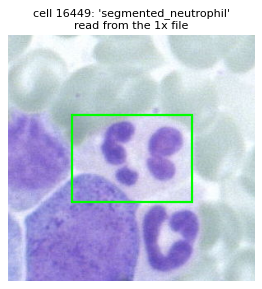

In [10]:
a = pydicom.dcmread(inv[inv.kind.str.contains("consensus")].path.iloc[0])
print("STEP 1 - the file")
print("   ", a.SeriesDescription, "| drawn on image ...", a.ReferencedImageSequence[0].ReferencedSOPInstanceUID[-8:],
      "| coordinates:", a.AnnotationCoordinateType, "| groups:", len(a.AnnotationGroupSequence))
print("    groups (label, number of boxes):", ", ".join(f"{g.AnnotationGroupLabel} ({g.NumberOfAnnotations})" for g in a.AnnotationGroupSequence[:6]), ", ...")

g = next(g for g in a.AnnotationGroupSequence if g.AnnotationGroupLabel == "segmented_neutrophil")
t = g.AnnotationPropertyTypeCodeSequence[0]
print("\nSTEP 2 - one group")
print(f"    AnnotationGroupLabel = '{g.AnnotationGroupLabel}'  (coded as {t.CodingSchemeDesignator}:{t.CodeValue} '{t.CodeMeaning}')")
print(f"    GraphicType = {g.GraphicType}, NumberOfAnnotations = {g.NumberOfAnnotations}")

flat = np.frombuffer(g.PointCoordinatesData, "<f4")
corners = flat.reshape(-1, 4, 2)[0]
(x0, y0), (x1, y1) = corners.min(axis=0), corners.max(axis=0)
print("\nSTEP 3 - PointCoordinatesData (where)")
print(f"    one flat list of {len(flat)} numbers = {g.NumberOfAnnotations} boxes x 4 corners x (x, y)")
print("    first 8 numbers         :", flat[:8].tolist())
print("    = 4 corners of box 1    :", corners.tolist())
print(f"    = rectangle             : x={x0:.0f}, y={y0:.0f}, w={x1 - x0:.0f}, h={y1 - y0:.0f}  (1x pixels)")

print("\nSTEP 4 - MeasurementsSequence (which cell, which ROI)")
meas = {m.ConceptNameCodeSequence[0].CodeMeaning: np.frombuffer(m.MeasurementValuesSequence[0].FloatingPointValues, "<f4").astype(int)
        for m in g.MeasurementsSequence}
for name, v in meas.items():
    print(f"    {name:42s} first values {v[:5].tolist()} ...  -> box 1: {v[0]}")
CELL_ID, ROI_ID = meas["single cell identifier"][0], meas["Referenced Region of Interest Identifier"][0]

print(f"\nRESULT: box 1 of group '{g.AnnotationGroupLabel}' = cell {CELL_ID} in ROI {ROI_ID} at x={x0:.0f}, y={y0:.0f}, {x1 - x0:.0f} x {y1 - y0:.0f} px")

# the same cell in the other annotation files (same box, possibly another label)
print("\nthe same cell id in the other files:")
for p in inv[inv.kind.str.startswith("Cell bounding")].path:
    b = pydicom.dcmread(p)
    hits = [gg.AnnotationGroupLabel for gg in b.AnnotationGroupSequence for m in gg.MeasurementsSequence
            if m.ConceptNameCodeSequence[0].CodeMeaning == "single cell identifier"
            and CELL_ID in np.frombuffer(m.MeasurementValuesSequence[0].FloatingPointValues, "<f4").astype(int)]
    name = "consensus" if "consensus" in b.SeriesDescription else b.SeriesDescription.split("; ")[-1]
    print(f"    {name:22s} -> {hits[0] if hits else '(not labelled in this session)'}")

img = read_window(FULL, (x0 + x1) / 2, (y0 + y1) / 2, 300)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(img); ax.add_patch(Rectangle((150 - (x1 - x0) / 2, 150 - (y1 - y0) / 2), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2))
ax.set_title(f"cell {CELL_ID}: '{g.AnnotationGroupLabel}'\nread from the 1x file", fontsize=10); ax.axis("off"); plt.show()

**So one annotation = group label (what) + 4 corners (where) + measurements (which cell id, which ROI).**
The ROI file uses exactly the same format: one group with 2 rectangles, and the measurement `Image Region` holds the ROI id (100, 101).
The 5 session files and the consensus file contain the **same boxes**; only the group (= label) a box sits in can differ.

### Full list of attributes of one group (for reference)

In [11]:
g = a.AnnotationGroupSequence[0]
print("attributes of group 1:")
for e in g:
    v = (f"<sequence, {len(e.value)}>" if e.VR == "SQ" else f"<{len(e.value)} bytes>" if e.VR in ("OF", "OD", "OL") else e.value)
    print(f"   {e.keyword:40s} {v}")
allp = np.concatenate([np.frombuffer(gg.PointCoordinatesData, "<f4").reshape(-1, 4, 2) for gg in a.AnnotationGroupSequence])
print("\nevery rectangle axis-aligned (2 distinct x and 2 distinct y per box):",
      all(len(set(p[:, 0])) == 2 and len(set(p[:, 1])) == 2 for p in allp))
for m in g.MeasurementsSequence:
    print("measurement:", m.ConceptNameCodeSequence[0].CodeMeaning, "| unit:", m.MeasurementUnitsCodeSequence[0].CodeValue)

attributes of group 1:
   AnnotationGroupNumber                    1
   PointCoordinatesData                     <288 bytes>
   MeasurementsSequence                     <sequence, 2>
   AnnotationGroupUID                       1.2.826.0.1.3680043.10.511.3.62477201924165070447297440019245293
   AnnotationGroupLabel                     artifact
   AnnotationGroupGenerationType            MANUAL
   AnnotationPropertyCategoryCodeSequence   <sequence, 1>
   AnnotationPropertyTypeCodeSequence       <sequence, 1>
   NumberOfAnnotations                      9
   AnnotationAppliesToAllOpticalPaths       YES
   GraphicType                              RECTANGLE

every rectangle axis-aligned (2 distinct x and 2 distinct y per box): True
measurement: single cell identifier | unit: 1
measurement: Referenced Region of Interest Identifier | unit: 1


### From files to one table
The same 4 steps for every group of every file give one table with **one row per box**:
`x, y, w, h` (1x pixels), `label` (= group), `cell_id`, `roi_id`, and `source` (= which file: `session_0` ... `session_4`, `consensus`).

In [12]:
def session_name(path):
    s = path.name
    if "Monolayer" in s: return "roi"
    if "consensus" in s: return "consensus"
    return "session_" + re.search(r"session_ (\d+)", s).group(1)

def read_ann(path):
    # all rectangles of one ANN file -> DataFrame, full-res pixel coordinates
    a, out = pydicom.dcmread(path), []
    for g in a.AnnotationGroupSequence:
        assert g.GraphicType == "RECTANGLE"
        pts = np.frombuffer(g.PointCoordinatesData, "<f4").reshape(-1, 4, 2).astype(float)
        mn, mx = pts.min(axis=1), pts.max(axis=1)
        d = pd.DataFrame({"x": mn[:, 0], "y": mn[:, 1], "w": mx[:, 0] - mn[:, 0], "h": mx[:, 1] - mn[:, 1],
                          "label": g.AnnotationGroupLabel,
                          "code": f"{g.AnnotationPropertyTypeCodeSequence[0].CodingSchemeDesignator}:{g.AnnotationPropertyTypeCodeSequence[0].CodeValue}",
                          "category": g.AnnotationPropertyCategoryCodeSequence[0].CodeMeaning})
        for m in g.MeasurementsSequence:
            v = np.frombuffer(m.MeasurementValuesSequence[0].FloatingPointValues, "<f4")
            assert len(v) == len(pts)
            d[m.ConceptNameCodeSequence[0].CodeMeaning] = v.astype(int)
        out.append(d)
    return pd.concat(out, ignore_index=True).assign(source=session_name(path))

ann = pd.concat([read_ann(p) for p in ann_files.path], ignore_index=True)
ann = ann.rename(columns={"single cell identifier": "cell_id", "Referenced Region of Interest Identifier": "roi_id", "Image Region": "region"})

rois = ann[ann.source == "roi"].assign(roi_id=lambda d: d.region.astype(int))[["roi_id", "x", "y", "w", "h"]].reset_index(drop=True)
boxes = ann[ann.source != "roi"].drop(columns="region").astype({"cell_id": int, "roi_id": int})
display(rois.assign(w_um=rois.w * FULL.ps_x * 1000, h_um=rois.h * FULL.ps_y * 1000))
display(boxes.groupby("source").agg(boxes=("cell_id", "size"), unique_cells=("cell_id", "nunique"), labels=("label", "nunique")))

,roi_id,x,y,w,h,w_um,h_um
0,100,26100.0,196503.0,2048.0,2048.0,226.395248,226.762105
1,101,147728.0,151468.0,2048.0,2048.0,226.395248,226.762105


,boxes,unique_cells,labels
source,,,
consensus,416,413,32
session_0,416,413,32
session_1,416,413,31
session_2,60,57,18
session_3,25,22,13
session_4,22,20,8


In [13]:
labels = (boxes[boxes.source == "consensus"].groupby(["label", "code", "category"]).size().rename("n")
          .reset_index().sort_values("n", ascending=False).reset_index(drop=True))
display(labels)

,label,code,category,n
0,technically_unfit,DCM:111235,Spatial and relational concepts,115
1,segmented_neutrophil,SCT:80153006,Anatomical structure,65
2,neutrophilic_myelocyte,SCT:4717004,Anatomical structure,49
3,neutrophilic_band,SCT:702697008,Anatomical structure,31
4,damaged_cell,SCT:37782003,Morphologically abnormal structure,25
5,neutrophilic_metamyelocyte,SCT:50134008,Anatomical structure,22
6,promyelocyte,SCT:43446009,Anatomical structure,19
7,no_consensus_found,SCT:414387006,Anatomical structure,17
8,artifact,SCT:47973001,Physical object,9
9,eosinophilic_myelocyte,SCT:90961003,Anatomical structure,9


## 5. Integrity checks
- Are the boxes identical across all sessions (same cell id -> same rectangle)?
- Are cell ids unique?
- Does the stored `roi_id` match the geometry (box inside its ROI)?

In [14]:
geo = boxes.groupby("cell_id")[["x", "y", "w", "h"]].nunique()
print("cell ids whose rectangle differs between files:", int((geo > 1).any(axis=1).sum()))

dup = boxes[boxes.duplicated(["source", "cell_id"], keep=False)].sort_values(["cell_id", "source"])
print("cell ids that occur twice inside one file:", sorted(dup.cell_id.unique()))
display(dup.pivot_table(index=["cell_id", "source"], values="label", aggfunc=" | ".join))

cell ids whose rectangle differs between files: 0
cell ids that occur twice inside one file: [np.int64(16255), np.int64(16420), np.int64(16633)]


label
cell_id source                                                                 
16255   consensus                        no_consensus_found | technically_unfit
        session_0                              damaged_cell | neutrophilic_band
        session_1  degranulated_neutrophilic_myelocyte | neutrophilic_myelocyte
        session_2  degranulated_neutrophilic_myelocyte | neutrophilic_myelocyte
        session_3                neutrophilic_band | neutrophilic_metamyelocyte
        session_4                     damaged_cell | neutrophilic_metamyelocyte
16420   consensus                        no_consensus_found | technically_unfit
        session_0                         damaged_cell | eosinophilic_myelocyte
        session_1                         technically_unfit | technically_unfit
        session_2                                    promyelocyte | smudge_cell
        session_3                          eosinophilic_myelocyte | smudge_cell
        session_4                                   damaged_cell | promyelocyte
16633   consensus                             damaged_cell | no_consensus_found
        session_0                              damaged_cell | eosinophilic_band
        session_1                   segmented_eosinophil | segmented_eosinophil
        session_2               eosinophilic_myelocyte | eosinophilic_myelocyte
        session_3                              damaged_cell | eosinophilic_band

The 3 duplicated ids occur twice in **every** file, with the same rectangle but two different labels each time – so they are most
likely two different physical cells that got the same id during data conversion (or one box labelled twice). They are excluded from the
inter-rater analysis below and should be reviewed (or dropped) before training.

In [15]:
DUP_IDS = set(dup.cell_id)
cons = boxes[boxes.source == "consensus"].copy()

def inside(b, r, frac=1.0):
    # share of the box area lying inside ROI r
    ix = max(0, min(b.x + b.w, r.x + r.w) - max(b.x, r.x)); iy = max(0, min(b.y + b.h, r.y + r.h) - max(b.y, r.y))
    return ix * iy / (b.w * b.h)

R = rois.set_index("roi_id")
cons["inside_frac"] = [inside(b, R.loc[b.roi_id]) for b in cons.itertuples()]
cx, cy = cons.x + cons.w / 2, cons.y + cons.h / 2
cons["centre_in_roi"] = [(R.loc[r].x <= x <= R.loc[r].x + R.loc[r].w) and (R.loc[r].y <= y <= R.loc[r].y + R.loc[r].h)
                         for r, x, y in zip(cons.roi_id, cx, cy)]
print("boxes fully inside their ROI:", (cons.inside_frac == 1).sum(), "| partly outside:", (cons.inside_frac < 1).sum(),
      "| centre outside ROI:", (~cons.centre_in_roi).sum(), "| completely outside:", (cons.inside_frac == 0).sum())
print("box area inside ROI for the partly-outside boxes:\n", cons.loc[cons.inside_frac < 1, "inside_frac"].describe().round(2).to_string())

boxes fully inside their ROI: 348 | partly outside: 68 | centre outside ROI: 27 | completely outside: 0
box area inside ROI for the partly-outside boxes:
 count    68.00
mean      0.58
std       0.30
min       0.03
25%       0.36
50%       0.57
75%       0.85
max       0.97


ROIs were annotated as "classify every cell that touches this square": 68 of 416 boxes (16 %) straddle the ROI border,
on average with only ~58 % of their area inside. For training on ROI crops this means **crops must be padded** (or boxes clipped).

## 6. Annotation protocol: 5 sessions vs. consensus

Each `annotation session_k` file is one annotator pass; the `consensus` file is the final label.
Below: one row per cell, one column per session.

In [16]:
lab = (boxes[~boxes.cell_id.isin(DUP_IDS)].pivot(index="cell_id", columns="source", values="label")
       [["session_0", "session_1", "session_2", "session_3", "session_4", "consensus"]])
S = ["session_0", "session_1", "session_2", "session_3", "session_4"]
lab["n_votes"] = lab[S].notna().sum(axis=1)
print("cells labelled per session:\n" + lab[S].notna().sum().to_string())
print("\ncells by number of annotators:\n" + lab.n_votes.value_counts().sort_index().to_string())

disagree01 = lab.session_0 != lab.session_1
print(f"\nsession_0 vs session_1 disagree on {disagree01.sum()} of {len(lab)} cells ({disagree01.mean():.1%})")
seen2 = lab.session_2.notna()
print(f"session_2 labelled {seen2.sum()} cells: all {(seen2 & disagree01).sum()} disagreements + {(seen2 & ~disagree01).sum()} cells where 0 and 1 agreed")
print("  agreed-but-escalated cells by label:", lab[seen2 & ~disagree01].session_0.value_counts().to_dict())
print("session_3 cells subset of session_2:", set(lab.index[lab.session_3.notna()]) <= set(lab.index[lab.session_2.notna()]),
      "| session_4 subset of session_3:", set(lab.index[lab.session_4.notna()]) <= set(lab.index[lab.session_3.notna()]))

cells labelled per session:
source
session_0    410
session_1    410
session_2     54
session_3     19
session_4     18

cells by number of annotators:
n_votes
2    356
3     35
4      1
5     18

session_0 vs session_1 disagree on 37 of 410 cells (9.0%)
session_2 labelled 54 cells: all 37 disagreements + 17 cells where 0 and 1 agreed
  agreed-but-escalated cells by label: {'technically_unfit': 10, 'neutrophilic_myelocyte': 2, 'damaged_cell': 2, 'neutrophilic_metamyelocyte': 1, 'neutrophilic_band': 1, 'degranulated_neutrophilic_metamyelocyte': 1}
session_3 cells subset of session_2: True | session_4 subset of session_3: True


So the protocol is **escalation**: two annotators label everything; every disagreement goes to a 3rd annotator
(plus 17 cells where the first two agreed, mostly `technically_unfit` – no obvious rule, possibly a QA sample),
and the cells still unresolved go to a 4th and 5th. Hypothesis for the consensus rule: *a label wins if it has an absolute
majority (> 50 %) of the votes cast, otherwise `no_consensus_found`*. Check:

In [17]:
def majority_rule(row):
    votes = [v for v in row[S] if isinstance(v, str)]
    lbl, n = collections.Counter(votes).most_common(1)[0]
    return lbl if n > len(votes) / 2 else "no_consensus_found"

lab["rule"] = lab.apply(majority_rule, axis=1)
print("consensus reproduced by 'absolute majority' rule:", (lab.rule == lab.consensus).mean(), f"({(lab.rule == lab.consensus).sum()}/{len(lab)})")
display(lab[lab.n_votes > 2].sort_values("n_votes").drop(columns="rule"))

consensus reproduced by 'absolute majority' rule: 1.0 (410/410)


source,session_0,session_1,session_2,session_3,session_4,consensus,n_votes
cell_id,,,,,,,
16469,technically_unfit,degranulated_neutrophilic_myelocyte,degranulated_neutrophilic_myelocyte,NaN,NaN,degranulated_neutrophilic_myelocyte,3
16472,technically_unfit,technically_unfit,neutrophilic_metamyelocyte,NaN,NaN,technically_unfit,3
16500,technically_unfit,neutrophilic_metamyelocyte,technically_unfit,NaN,NaN,technically_unfit,3
16508,damaged_cell,neutrophilic_myelocyte,damaged_cell,NaN,NaN,damaged_cell,3
16517,technically_unfit,myeloid_precursor_cell,myeloid_precursor_cell,NaN,NaN,myeloid_precursor_cell,3
16532,technically_unfit,neutrophilic_metamyelocyte,neutrophilic_metamyelocyte,NaN,NaN,neutrophilic_metamyelocyte,3
16533,degranulated_neutrophilic_metamyelocyte,degranulated_neutrophilic_metamyelocyte,degranulated_neutrophilic_metamyelocyte,NaN,NaN,degranulated_neutrophilic_metamyelocyte,3
16541,technically_unfit,technically_unfit,neutrophilic_metamyelocyte,NaN,NaN,technically_unfit,3
16564,technically_unfit,technically_unfit,myeloid_precursor_cell,NaN,NaN,technically_unfit,3


session_0 vs session_1: raw agreement 0.910, Cohen's kappa 0.895


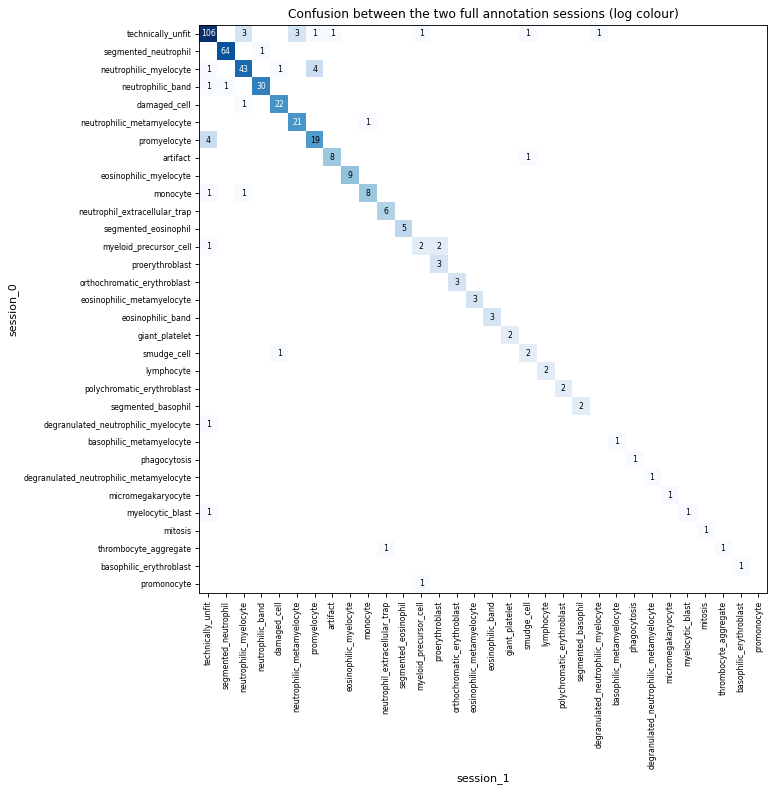

most frequent disagreement pairs:
(promyelocyte, technically_unfit)                           5.0
(neutrophilic_myelocyte, technically_unfit)                 4.0
(neutrophilic_myelocyte, promyelocyte)                      4.0
(neutrophilic_metamyelocyte, technically_unfit)             3.0
(damaged_cell, neutrophilic_myelocyte)                      2.0
(degranulated_neutrophilic_myelocyte, technically_unfit)    2.0
(myeloid_precursor_cell, proerythroblast)                   2.0
(neutrophilic_band, segmented_neutrophil)                   2.0
(myeloid_precursor_cell, technically_unfit)                 2.0
(artifact, smudge_cell)                                     1.0


In [18]:
# agreement between the two full annotators, and which labels they confuse
both = lab[["session_0", "session_1"]]
ct = pd.crosstab(both.session_0, both.session_1)
cls = sorted(set(ct.index) | set(ct.columns), key=lambda c: -lab.consensus.eq(c).sum())
ct = ct.reindex(index=cls, columns=cls, fill_value=0)

p_o = np.trace(ct.values) / ct.values.sum()
p_e = (ct.sum(1).values * ct.sum(0).values).sum() / ct.values.sum() ** 2
print(f"session_0 vs session_1: raw agreement {p_o:.3f}, Cohen's kappa {(p_o - p_e) / (1 - p_e):.3f}")

fig, ax = plt.subplots(figsize=(12, 10))
m = np.where(ct.values == 0, np.nan, ct.values)
ax.imshow(np.log1p(m), cmap="Blues")
for i, j in zip(*np.nonzero(ct.values)):
    ax.text(j, i, ct.values[i, j], ha="center", va="center", fontsize=7, color="white" if i == j and ct.values[i, j] > 20 else "black")
ax.set_xticks(range(len(cls)), cls, rotation=90, fontsize=7); ax.set_yticks(range(len(cls)), cls, fontsize=7)
ax.set(xlabel="session_1", ylabel="session_0", title="Confusion between the two full annotation sessions (log colour)")
plt.tight_layout(); plt.show()

off = ct.where(~np.eye(len(cls), dtype=bool)).stack()
pairs = off[off > 0].groupby(lambda ij: tuple(sorted(ij))).sum().sort_values(ascending=False)
print("most frequent disagreement pairs:\n" + pairs.head(10).to_string())

## 7. Putting it together: ROIs and cells on the image

ROI positions on the whole slide, then each ROI read from the **full-resolution** file (2048 x 2048 px plus a margin, i.e. 4-9 tiles)
with all consensus boxes drawn on top.
ROI set from the expert and is in the ANN files.

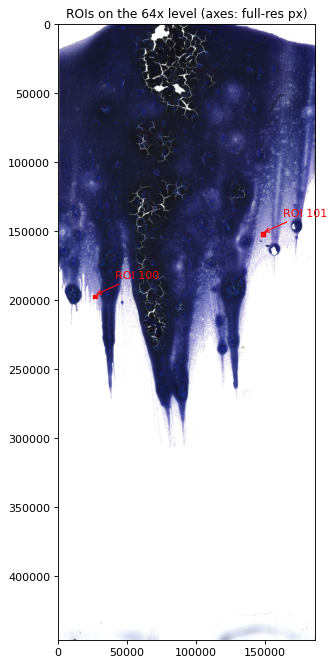

In [19]:
order = cons.label.value_counts().index.tolist()
cmap = plt.get_cmap("tab20")
COL = {l: (cmap(i) if i < 20 else (0.55, 0.55, 0.55, 1)) for i, l in enumerate(order)}

fig, ax = plt.subplots(figsize=(5, 10))
ax.imshow(img64, extent=(0, FULL.W, FULL.H, 0))
for r in rois.itertuples():
    ax.add_patch(Rectangle((r.x, r.y), r.w, r.h, fill=False, ec="red", lw=2))
    ax.annotate(f"ROI {r.roi_id}", (r.x, r.y), xytext=(r.x + 15000, r.y - 12000), color="red", arrowprops=dict(arrowstyle="->", color="red"))
ax.set_title("ROIs on the 64x level (axes: full-res px)"); plt.show()

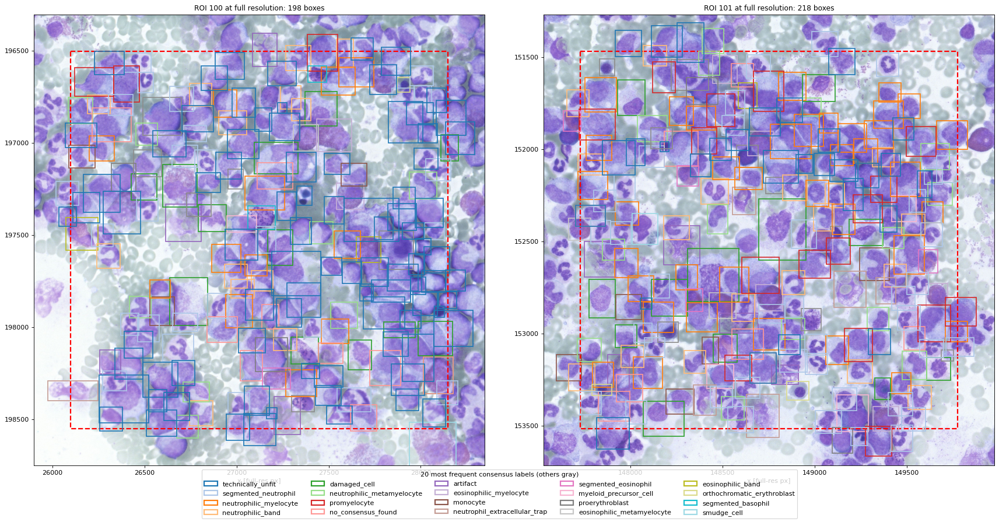

In [20]:
PAD = 200                                                     # full-res px of margin around each ROI
roi_img = {}
for r in rois.itertuples():
    roi_img[r.roi_id] = (FULL.read_region(r.x - PAD, r.y - PAD, r.w + 2 * PAD, r.h + 2 * PAD), (r.x - PAD, r.y - PAD))

fig, axs = plt.subplots(1, len(rois), figsize=(11 * len(rois), 11))
for a, r in zip(np.atleast_1d(axs), rois.itertuples()):
    img, (ox, oy) = roi_img[r.roi_id]
    a.imshow(img, extent=(ox, ox + img.shape[1], oy + img.shape[0], oy))
    a.add_patch(Rectangle((r.x, r.y), r.w, r.h, fill=False, ec="red", lw=2, ls="--"))
    for c in cons[cons.roi_id == r.roi_id].itertuples():
        a.add_patch(Rectangle((c.x, c.y), c.w, c.h, fill=False, ec=COL[c.label], lw=1.5))
    a.set_title(f"ROI {r.roi_id} at full resolution: {(cons.roi_id == r.roi_id).sum()} boxes"); a.set_xlabel("x [full-res px]")
fig.legend([Rectangle((0, 0), 1, 1, fc="none", ec=COL[l], lw=2) for l in order[:20]], order[:20],
           loc="lower center", ncol=5, fontsize=10, title="20 most frequent consensus labels (others gray)")
plt.tight_layout(rect=(0, 0.09, 1, 1)); plt.show()

### Cell gallery
Up to 8 example cells per consensus label, cropped from the full-res ROI images with a fixed 200 x 200 px window (22 um)
centred on the box – this is roughly what a cell classifier would see.

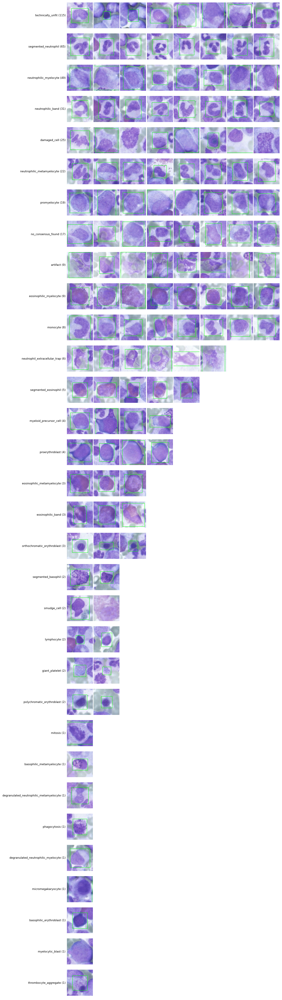

In [21]:
WIN, PER = 200, 8

def cell_crop(c):
    img, (ox, oy) = roi_img[c.roi_id]
    cx, cy = int(c.x + c.w / 2 - ox), int(c.y + c.h / 2 - oy)
    out = np.full((WIN, WIN, 3), 255, np.uint8)
    y0, x0 = cy - WIN // 2, cx - WIN // 2
    sy0, sx0, sy1, sx1 = max(y0, 0), max(x0, 0), min(y0 + WIN, img.shape[0]), min(x0 + WIN, img.shape[1])
    out[sy0 - y0:sy1 - y0, sx0 - x0:sx1 - x0] = img[sy0:sy1, sx0:sx1]
    return out, (c.x - ox - x0, c.y - oy - y0)

fig, axs = plt.subplots(len(order), PER, figsize=(PER * 1.6, len(order) * 1.65))
for i, l in enumerate(order):
    s = cons[cons.label == l].sample(min(PER, (cons.label == l).sum()), random_state=0)
    for j in range(PER):
        a = axs[i, j]; a.axis("off")
        if j < len(s):
            c = s.iloc[j]; img, (bx, by) = cell_crop(c)
            a.imshow(img); a.add_patch(Rectangle((bx, by), c.w, c.h, fill=False, ec="lime", lw=0.8))
    axs[i, 0].text(-10, WIN / 2, f"{l} ({(cons.label == l).sum()})", ha="right", va="center", fontsize=8)
plt.subplots_adjust(left=0.22, wspace=0.03, hspace=0.05); plt.show()

## 8. Statistics

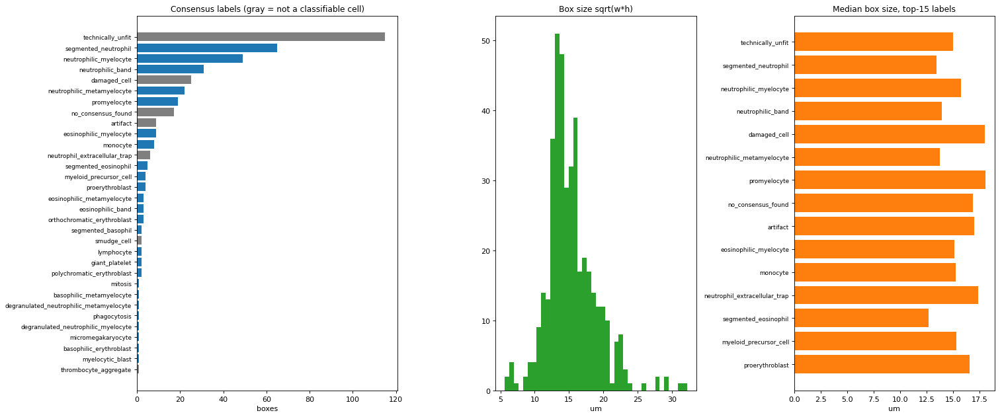

416 boxes, 32 labels; non-cell labels: 175 boxes (42%); classifiable cells: 241
labels with <= 2 boxes: 14, with exactly 1: 9
box size: median 134 x 135 px = 14.8 x 14.9 um, range 50-298 px


label,technically_unfit,segmented_neutrophil,neutrophilic_myelocyte,neutrophilic_band,damaged_cell,neutrophilic_metamyelocyte,promyelocyte,no_consensus_found,artifact,eosinophilic_myelocyte,monocyte,neutrophil_extracellular_trap,segmented_eosinophil,myeloid_precursor_cell,proerythroblast,eosinophilic_metamyelocyte,eosinophilic_band,orthochromatic_erythroblast,segmented_basophil,smudge_cell,lymphocyte,giant_platelet,polychromatic_erythroblast,mitosis,basophilic_metamyelocyte,degranulated_neutrophilic_metamyelocyte,phagocytosis,degranulated_neutrophilic_myelocyte,micromegakaryocyte,basophilic_erythroblast,myelocytic_blast,thrombocyte_aggregate
roi_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
100,86,26,12,13,13,8,3,9,4,3,3,1,1,1,2,1,2,1,2,1,1,0,0,0,1,1,0,1,1,0,1,0
101,29,39,37,18,12,14,16,8,5,6,5,5,4,3,2,2,1,2,0,1,1,2,2,1,0,0,1,0,0,1,0,1
total,115,65,49,31,25,22,19,17,9,9,8,6,5,4,4,3,3,3,2,2,2,2,2,1,1,1,1,1,1,1,1,1


In [22]:
NON_CELL = ["technically_unfit", "damaged_cell", "artifact", "no_consensus_found", "smudge_cell",
            "neutrophil_extracellular_trap", "thrombocyte_aggregate"]
counts = cons.label.value_counts()
um = FULL.ps_x * 1000

fig, axs = plt.subplots(1, 3, figsize=(19, 8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
axs[0].barh(counts.index[::-1], counts.values[::-1], color=["tab:gray" if l in NON_CELL else "tab:blue" for l in counts.index[::-1]])
axs[0].set(title="Consensus labels (gray = not a classifiable cell)", xlabel="boxes"); axs[0].tick_params(axis="y", labelsize=8)
axs[1].hist(np.sqrt(cons.w * cons.h) * um, bins=40, color="tab:green")
axs[1].set(title="Box size sqrt(w*h)", xlabel="um")
med = cons.assign(s=np.sqrt(cons.w * cons.h) * um).groupby("label").s.median().reindex(order[:15])
axs[2].barh(med.index[::-1], med.values[::-1], color="tab:orange"); axs[2].set(title="Median box size, top-15 labels", xlabel="um")
axs[2].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

print(f"{len(cons)} boxes, {cons.label.nunique()} labels; non-cell labels: {cons.label.isin(NON_CELL).sum()} boxes "
      f"({cons.label.isin(NON_CELL).mean():.0%}); classifiable cells: {(~cons.label.isin(NON_CELL)).sum()}")
print(f"labels with <= 2 boxes: {(counts <= 2).sum()}, with exactly 1: {(counts == 1).sum()}")
print(f"box size: median {cons.w.median():.0f} x {cons.h.median():.0f} px = {cons.w.median()*um:.1f} x {cons.h.median()*um:.1f} um, "
      f"range {cons.w.min():.0f}-{cons.w.max():.0f} px")
display(pd.crosstab(cons.label, cons.roi_id).loc[order].assign(total=lambda d: d.sum(axis=1)).T)

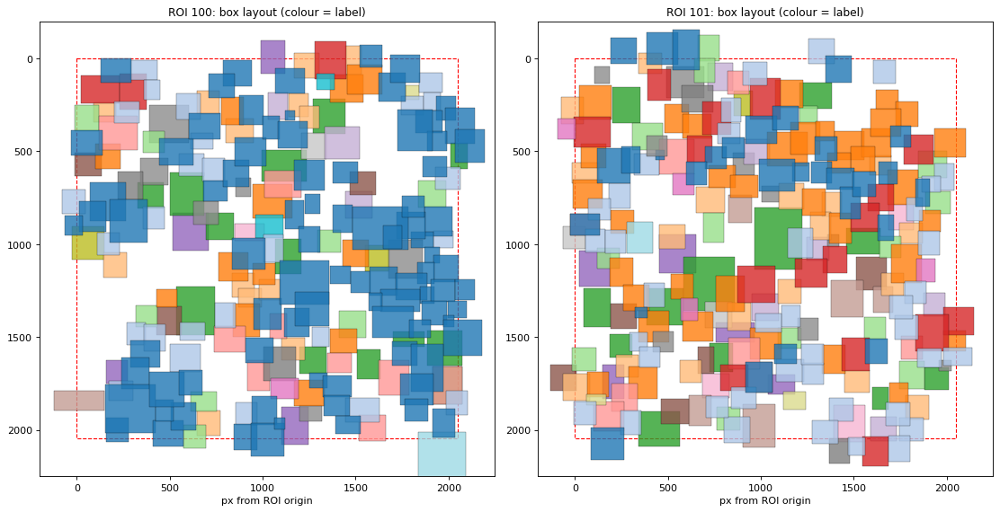

sum of box areas / ROI area: {100: np.float64(1.0), 101: np.float64(1.02)}


In [23]:
fig, axs = plt.subplots(1, len(rois), figsize=(7 * len(rois), 7))
for a, r in zip(np.atleast_1d(axs), rois.itertuples()):
    a.add_patch(Rectangle((0, 0), r.w, r.h, fill=False, ec="red", ls="--"))
    s = cons[cons.roi_id == r.roi_id]
    for c in s.itertuples():
        a.add_patch(Rectangle((c.x - r.x, c.y - r.y), c.w, c.h, fc=COL[c.label], ec="k", lw=0.3, alpha=0.8))
    a.set(xlim=(-PAD, r.w + PAD), ylim=(r.h + PAD, -PAD), title=f"ROI {r.roi_id}: box layout (colour = label)", xlabel="px from ROI origin")
    a.set_aspect("equal")
plt.tight_layout(); plt.show()
cov = {r.roi_id: (cons[cons.roi_id == r.roi_id].eval("w*h").sum() / (r.w * r.h)) for r in rois.itertuples()}
print("sum of box areas / ROI area:", {k: round(v, 2) for k, v in cov.items()})

## 9. Clinical data
Clinical DICOM tags and the lab CSV (semicolon separated, one row per patient, LOINC codes as column names).
LOINC names below are a manual mapping – verify against loinc.org before use.

In [24]:
tags = ["PatientID", "PatientSex", "PatientAge", "AdmittingDiagnosesDescription", "ClinicalTrialProtocolID",
        "StudyDescription", "ContainerIdentifier", "AcquisitionDateTime"]
display(pd.Series({t: str(FULL.hdr.get(t, "")) for t in tags}, name="value").to_frame())
dx = FULL.hdr.AdmittingDiagnosesCodeSequence[0]
print(f"diagnosis code: {dx.CodingSchemeDesignator} {dx.CodeValue} - {dx.CodeMeaning}; "
      f"age {FULL.hdr.PatientAge} = {int(FULL.hdr.PatientAge[:-1]) / 12:.0f} years")

LOINC = {"14804-9": "LDH [U/L]", "1743-4": "ALT [U/L]", "20570-8": "Hematocrit [%]", "2160-0": "Creatinine [mg/dL]",
         "28539-5": "MCH [pg]", "28540-3": "MCHC [g/dL]", "30239-8": "AST [U/L]", "30385-9": "RDW [%]", "30428-7": "MCV [fL]",
         "3084-1": "Uric acid [mg/dL]", "6690-2": "Leukocytes [10^3/uL]", "714-6": "Eosinophils/100 leukocytes [%]",
         "718-7": "Hemoglobin [g/dL]", "737-7": "Lymphocytes/100 leukocytes [%]", "744-3": "Monocytes/100 leukocytes [%]",
         "769-0": "Neutrophils/100 leukocytes [%]", "777-3": "Platelets [10^3/uL]", "789-8": "Erythrocytes [10^6/uL]"}
labs = pd.read_csv(LAB_FILE, sep=";").set_index("patient_id").T
labs.insert(0, "name (LOINC)", labs.index.map(LOINC))
display(labs)

,value
PatientID,A6BBC91AE73DD21C0533F735470A9CD0
PatientSex,F
PatientAge,204M
AdmittingDiagnosesDescription,"Chronic Phase Chronic Myeloid Leukemia, BCR-ABL1 Positive"
ClinicalTrialProtocolID,BoneMarrowWSI-PediatricLeukemia
StudyDescription,"Bone marrow aspirate smear, pediatric leukemia"
ContainerIdentifier,A6BBC91AE73DD21C0533F735470A9CD0_1_bm
AcquisitionDateTime,20220521093149


diagnosis code: NCIt C3175 - Chronic Phase Chronic Myeloid Leukemia, BCR-ABL1 Positive; age 204M = 17 years


patient_id,name (LOINC),A6BBC91AE73DD21C0533F735470A9CD0,F7177163C833DFF4B38FC8D2872F1EC6
14804-9,LDH [U/L],NaN,NaN
1743-4,ALT [U/L],NaN,19.0
20570-8,Hematocrit [%],37.60,17.5
2160-0,Creatinine [mg/dL],NaN,0.6
28539-5,MCH [pg],25.60,32.0
28540-3,MCHC [g/dL],30.80,36.6
30239-8,AST [U/L],NaN,48.0
30385-9,RDW [%],18.70,NaN
30428-7,MCV [fL],83.10,87.5
3084-1,Uric acid [mg/dL],NaN,13.0


For this patient: **leukocytes 150.5 x 10^3/uL** (normal ~4-11), platelets 512 x 10^3/uL (high), Hb 11.6 g/dL (low),
54 % neutrophils – the typical blood picture of chronic-phase CML (massive expansion of the maturing granulocytic line).
This matches what the slide shows: the cell mix is dominated by neutrophilic maturation stages (myelocytes, bands, segmented neutrophils).

## 10. Findings & open questions
Numbers refer to the executed outputs above.

**Data structure**
- One patient = one WSI study: a 5-level pyramid (1x, 4x, 16x, 64x, 256x; full-res 0.1105 um/px, 186,257 x 446,170 px,
  79,352 JPEG tiles, 5.4 GB) + thumbnail + slide overview photo, and 7 annotation files.
- Downsampling factors are **exact powers of 4** (the old notebook's "16.08" came from dividing by the nominal 0.11 um instead of the
  real 0.11054 um).
- Tiles can be read individually in ~45 ms each (Extended Offset Table) – the full-res file never needs to be loaded.

**Annotations**
- All annotations are axis-aligned `RECTANGLE`s in **full-res pixel coordinates** (`2D`, referencing the full-res instance);
  for another level divide by 4^k.
- 2 ROIs (ids 100, 101) of 2048 x 2048 px (226 um) – "monolayer regions" where every cell was classified. Only ~0.1 mm^2 of a ~1000 mm^2 scan is labelled.
- 416 cell boxes (413 unique ids), median ~15 um, 32 labels; same rectangles in all 6 cell files – only the labels differ.
- Boxes are allowed to cross the ROI border (68 boxes = 16 % partly outside, none completely) -> pad ROI crops.
- The ROIs are densely packed: the summed box area is ~100 % of the ROI area.

**Annotation protocol**
- session_0 and session_1 label all cells: raw agreement 91 %, Cohen's kappa 0.90. All 37 disagreements (+17 agreed cells)
  go to session_2; unresolved ones to sessions 3 and 4.
- Consensus = **absolute majority of votes**, otherwise `no_consensus_found` – reproduced for every cell.
- Disagreements concentrate on (a) "classify at all vs `technically_unfit`" and (b) neighbouring stages of the neutrophil
  maturation (promyelocyte -> myelocyte -> metamyelocyte -> band -> segmented).

**Open questions / to decide before training**
1. The 3 duplicated cell ids (two labels on one rectangle in every file): drop, or ask the dataset authors?
2. Non-cell labels (`technically_unfit`, `damaged_cell`, `artifact`, `no_consensus_found`, ...) are 42 % of boxes (175 of 416); only 241 classifiable cells remain: drop, or keep as a reject class?
3. Extreme class imbalance and many classes with 1-2 examples per patient -> label grouping (e.g. by lineage/maturation) is probably needed; check counts over the whole cohort.
4. Use the session labels as soft labels (vote distribution) instead of only the consensus?
5. Which resolution for the model: 1x (0.11 um/px, cell ~135 px) vs 4x (cell ~34 px)? The level comparison in section 2: cells are still readable at 4x, gone at 16x.
6. Patient-level task: diagnosis is one label per patient (here CML) – how many patients/ROIs per diagnosis exist in the full dataset?
7. The second patient in `Data/` (`F717...`) only has the overview image and the ROI file locally – download its remaining files for a comparison.